[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch10-simple_workbook.ipynb)

# Words in pieces

A list of every word in chapters 1 to 54 of Pride and Prejudice still lacks
some words of chapters 55 to 61. How can a vocabulary of a few thousand
tokens spell every word of those chapters, `the` as one token and a rare
place name in pieces?

In [1]:
#@title Setup: run this cell first
import heapq
import os
import re
import urllib.request
from collections import Counter, defaultdict
from itertools import accumulate

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# Chapters 1 to 54 train: the word lists and the merges count them alone. Chapters 55 to 61 are held out,
# and the unknown words and the tokens per word are measured on them.
FIRST_HELD, LAST = 55, 61
EOW = "</w>"  # the end-of-word marker of the lecture: one symbol at the end of every word, counted like a letter
# Places the novel names. The rare name is the one both parts name that the training chapters name least;
# min keeps the first of a tie, in this order.
PLACES = ("longbourn", "netherfield", "meryton", "pemberley", "rosings", "hunsford", "lambton", "brighton", "london", "kent")
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


def yours(name, lo, hi, answered, say):  # a sentence on the student's setting, when it is valid and not yet answered
    x = globals().get(name)
    return say(x) if type(x) is int and lo <= x <= hi and x not in answered else ""


def bars(title, labels, values, xlabel, focus=None, fmt="%.2f"):  # one chart of labelled bars, the focus bar in red
    fig, ax = plt.subplots(figsize=(6, 0.3 * len(values) + 1.2), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=["C3" if x == focus else "C0" for x in labels])
    ax.bar_label(b, fmt=fmt, padding=2, fontsize=8)
    ax.xaxis.get_major_locator().set_params(integer=fmt == "%d")  # whole tokens on a chart of counts
    ax.set(title=title, xlabel=xlabel, xlim=(0, 1.25 * (max(values) or 1)), ylim=(len(values) - 0.5, -0.5))
    plt.show()


def join(s, p):  # the symbols s with every adjacent occurrence of the pair p merged into one, left to right
    out, j = [], 0
    while j < len(s):
        hit = tuple(s[j:j + 2]) == p
        out.append(s[j] + s[j + 1] if hit else s[j])
        j += 2 if hit else 1
    return out


# BPE on word types with counts, until each word is one symbol: [(pair, count, symbols removed)]. A tie goes to the
# pair seen first in the corpus as it stands: words in order of first use, then position in the word, the lecture's
# "first pair seen wins". The heap holds (-count, that word, that position, pair); an entry that no longer matches
# its pair's key is skipped.
def learn(counts):
    words, freq = [list(w) + [EOW] for w in counts], list(counts.values())
    pairs, where, merges, touched = Counter(), defaultdict(Counter), [], {}

    def tally(i, sign):  # add or remove the adjacent pairs of word i, and note each pair touched
        for q in zip(words[i], words[i][1:]):
            pairs[q] += sign * freq[i]
            where[q][i] += sign
            if not where[q][i]:
                del where[q][i]
            touched[q] = None

    def key(q):
        i = min(where[q])
        return -pairs[q], i, list(zip(words[i], words[i][1:])).index(q), q

    [tally(i, 1) for i in range(len(words))]
    heap = sorted(key(q) for q in pairs)  # a sorted list is a heap
    while heap:
        q = (entry := heapq.heappop(heap))[3]
        if pairs[q] <= 0 or entry != key(q):
            continue
        n, touched, removed = pairs[q], {}, 0
        for i in sorted(where[q]):
            tally(i, -1)
            new = join(words[i], q)
            removed += freq[i] * (len(words[i]) - len(new))
            words[i] = new
            tally(i, 1)
        merges.append((q, n, removed))
        [heapq.heappush(heap, key(r)) for r in touched if pairs[r] > 0]
    return merges


chapters = load_novel()
train, held = chapters[:FIRST_HELD - 1], chapters[FIRST_HELD - 1:LAST]
counts = Counter(w for c in train for w in c)  # the training chapters' word types with counts, in order of first use
held_counts = Counter(w for c in held for w in c)
train_words, held_words = sum(counts.values()), sum(held_counts.values())
merges = learn(counts)
rank = {p: r for r, (p, _, _) in enumerate(merges)}  # no pair of this text is merged twice
base = sorted({ch for w in counts for ch in w}) + [EOW]
# symbols[k]: the symbols of the training chapters after k merges, each merge removing what it joined
symbols = list(accumulate((r for _, _, r in merges), lambda a, b: a - b, initial=sum(n * (len(w) + 1) for w, n in counts.items())))
RARE = min((p for p in PLACES if counts[p] and held_counts[p]), key=lambda p: counts[p])


def segment(word, k):  # the first k merges in learned order: each round applies the next learned merge the word holds
    s, last = list(word) + [EOW], -1
    while (r := min((rank[q] for q in zip(s, s[1:]) if last < rank.get(q, k) < k), default=None)) is not None:
        s, last = join(s, merges[r][0]), r
    return s


def per_word(k):  # tokens per word of the held-out chapters after the first k merges
    return sum(n * len(segment(w, k)) for w, n in held_counts.items()) / held_words


# Step 1: a word list of the first n chapters, and the words of the held-out chapters it lacks.
def unknown(n):
    listed = set().union(*train[:whole("N", n, 1, len(train))])
    return [w for c in held for w in c if w not in listed]


def word_list(n):
    missing, label = unknown(n), lambda m: "chapter 1" if m == 1 else f"chapters 1 to {m}"
    print(f"a list of chapters 1 to {n}: {len(set().union(*train[:n])):,} different words. Chapters {FIRST_HELD} to {LAST}: {held_words:,} words, {len(missing):,} "
          f"missing from the list ({100 * len(missing) / held_words:.2f} per cent), {len(set(missing)):,} different ones, the first: {', '.join(list(dict.fromkeys(missing))[:8])}")
    ns = sorted({1, 2, 5, 10, 20, 40, len(train), n})
    bars("word lists of the first chapters", [label(m) for m in ns], [100 * len(unknown(m)) / held_words for m in ns],
         f"per cent of the words of chapters {FIRST_HELD} to {LAST} missing", focus=label(n))


# Step 2: the first merges, and the symbols per word of the training chapters after 0 to k merges in ten steps.
def first_merges(k):
    ks, label = sorted({round(whole("K", k, 0, len(merges)) * j / 10) for j in range(11)}), lambda j: f"{j:,} merge" + "s" * (j != 1)
    print("the first 10 merges: " + "; ".join(f"{a} + {b} at {n:,}" for (a, b), n, _ in merges[:10]) + f"\nafter {k:,} merges: {symbols[k] / train_words:.2f} "
          f"symbols per word in chapters 1 to {FIRST_HELD - 1}, from {symbols[0] / train_words:.2f}; {per_word(k):.2f} in the held-out chapters {FIRST_HELD} to {LAST}")
    bars(f"merges learned on chapters 1 to {FIRST_HELD - 1}", [label(j) for j in ks], [symbols[j] / train_words for j in ks], "symbols per word", focus=label(k))


# Step 3: a frequent word, a common name and the rare place name cut by the first k merges.
def cut(k):
    pieces = {w: segment(w, whole("K", k, 0, len(merges))) for w in ("the", "elizabeth", RARE)}
    print(f"after {k:,} merges: " + "; ".join(f"{w}, {counts[w]:,} times in chapters 1 to {FIRST_HELD - 1}: {' '.join(p)}" for w, p in pieces.items()))
    bars(f"the first {k:,} merges", [f"{w} ({counts[w]:,} times)" for w in pieces], [len(p) for p in pieces.values()], "tokens", fmt="%d")


display(Markdown(f"The novel: {len(chapters)} chapters. Chapters 1 to {FIRST_HELD - 1} train: {train_words:,} words, {len(counts):,} different ones, "
                 f"{len(base)} base symbols with `</w>`, and {len(merges):,} merges until each of their words is one token. Chapters {FIRST_HELD} "
                 f"to {LAST} are held out: {held_words:,} words. The rare place name: `{RARE}`, {counts[RARE]} times in the training chapters and {held_counts[RARE]} in the held-out ones."))

The novel: 61 chapters. Chapters 1 to 54 train: 107,695 words, 6,067 different ones, 28 base symbols with `</w>`, and 9,769 merges until each of their words is one token. Chapters 55 to 61 are held out: 14,479 words. The rare place name: `lambton`, 9 times in the training chapters and 1 in the held-out ones.

## 1. A word list and the words it lacks

A word-level vocabulary lists each word of its training text and maps every
other word to one unknown symbol, `[UNK]`. The cell lists the words of the
first `N` chapters and counts the words of chapters 55 to 61 missing from the
list, as a share of all their words. Run the cell with the first 10
chapters. Then set `N` to 54, every chapter before chapter 55: what share of
the held-out words does the list still lack?

a list of chapters 1 to 10: 2,269 different words. Chapters 55 to 61: 14,479 words, 1,461 missing from the list (10.09 per cent), 981 different ones, the first: confessed, dressed, dressing, finished, crying, sarah, forwarder, went


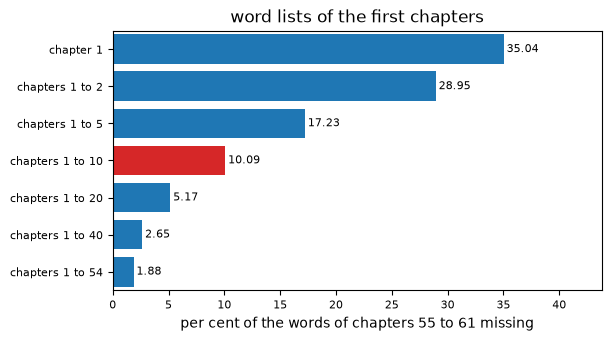

In [2]:
N = 10
word_list(N)

### Solution

In [3]:
m10, m54 = unknown(10), unknown(54)
display(Markdown(f"A list of chapters 1 to 10 lacks {100 * len(m10) / held_words:.2f} per cent of the words of chapters {FIRST_HELD} to {LAST}, and a list "
                 f"of all 54 training chapters {100 * len(m54) / held_words:.2f} per cent: {len(set(m54)):,} different words, such as "
                 f"{', '.join(list(dict.fromkeys(m54))[:3])} and {list(dict.fromkeys(m54))[3]}, go to `[UNK]` with every training chapter in the list."
                 + yours("N", 1, len(train), (10, 54), lambda n: f" With `N` at {n}, the list lacks {100 * len(unknown(n)) / held_words:.2f} per cent.")))

A list of chapters 1 to 10 lacks 10.09 per cent of the words of chapters 55 to 61, and a list of all 54 training chapters 1.88 per cent: 247 different words, such as sarah, forwarder, hang and sash, go to `[UNK]` with every training chapter in the list.

## 2. The first merges

BPE spells each word of chapters 1 to 54 in letters, ends it with the
end-of-word marker `</w>`, and counts every adjacent pair, each word as many
times as the chapters use it. Each merge joins the most frequent pair into one symbol and removes
one symbol for every occurrence of that pair. Run the cell for the first 10
merges. Then set `K` to 1,000: how many symbols per word do the training
chapters take after 1,000 merges?

the first 10 merges: e + </w> at 19,536; d + </w> at 12,291; t + h at 12,204; t + </w> at 11,741; s + </w> at 11,004; e + r at 9,995; i + n at 8,921; y + </w> at 7,982; a + n at 7,103; o + </w> at 5,632
after 10 merges: 4.41 symbols per word in chapters 1 to 54, from 5.40; 4.40 in the held-out chapters 55 to 61


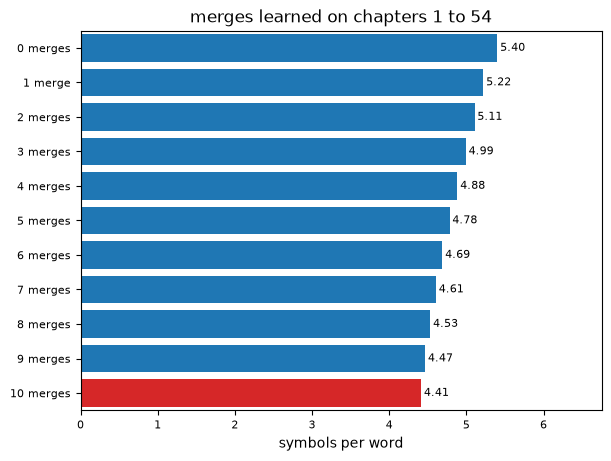

In [4]:
K = 10
first_merges(K)

### Solution

In [5]:
(a, b), n, _ = merges[0]
such = [f"`{w}`" for w, _ in counts.most_common() if a + b in w + EOW][:4]
display(Markdown(f"The first merge joins `{a}` and `{b}` at {n:,}, in words such as {', '.join(such[:-1])} and {such[-1]}; of the first 5 merges, "
                 f"{sum(q[1] == EOW for q, _, _ in merges[:5])} join a last letter to `</w>`. Chapters 1 to 54 take {symbols[0] / train_words:.2f} symbols per word before "
                 f"any merge, {symbols[10] / train_words:.2f} after 10 and {symbols[1000] / train_words:.2f} after 1,000; the first merge removed {merges[0][2]:,} symbols and "
                 f"the 1,000th {merges[999][2]:,}." + yours("K", 0, len(merges), (10, 1000), lambda k: f" With `K` at {k:,} they take {symbols[k] / train_words:.2f}.")))

The first merge joins `e` and `</w>` at 19,536, in words such as `the`, `she`, `he` and `be`; of the first 5 merges, 4 join a last letter to `</w>`. Chapters 1 to 54 take 5.40 symbols per word before any merge, 4.41 after 10 and 1.49 after 1,000; the first merge removed 19,536 symbols and the 1,000th 45.

## 3. Frequent and rare words

Encoding applies the merges in the order BPE learned them, so each word has
one segmentation. A pair counts once for every use of every word that holds
it, so the pairs of a frequent word win early merges and a rare word stays in
pieces through more merges. The cell cuts `the`, `elizabeth` and the rare
place name the setup printed with the first `K` merges. Run the cell with
1,000 merges. Then set `K` to 100: which of the words is still one token?

after 1,000 merges: the, 3,878 times in chapters 1 to 54: the</w>; elizabeth, 510 times in chapters 1 to 54: elizabeth</w>; lambton, 9 times in chapters 1 to 54: la mb ton</w>


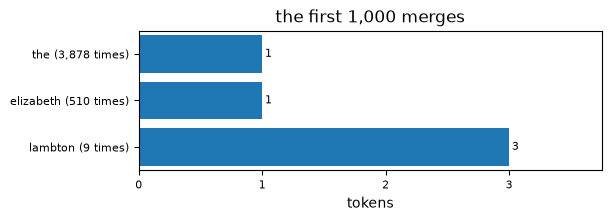

In [6]:
K = 1000
cut(K)

### Solution

In [7]:
one = {w: next(k for k in range(len(merges) + 1) if len(segment(w, k)) == 1) for w in ("the", "elizabeth", RARE)}
size = lambda k: "`the` takes {}, `elizabeth` {} and `{}` {}".format(len(segment("the", k)), len(segment("elizabeth", k)), RARE, len(segment(RARE, k)))  # noqa: E731
display(Markdown(f"After 1,000 merges {size(1000)} tokens, `{RARE}` cut as `{' '.join(segment(RARE, 1000))}`; after 100 merges {size(100)}. `{RARE}`, "
                 f"{counts[RARE]} times in the training chapters, is one token from merge {one[RARE]:,} on, `elizabeth` from merge {one['elizabeth']:,} and `the` "
                 f"from merge {one['the']}." + yours("K", 0, len(merges), (1000, 100), lambda k: f" With `K` at {k:,}, {size(k)}.")))

After 1,000 merges `the` takes 1, `elizabeth` 1 and `lambton` 3 tokens, `lambton` cut as `la mb ton</w>`; after 100 merges `the` takes 1, `elizabeth` 5 and `lambton` 6. `lambton`, 9 times in the training chapters, is one token from merge 2,821 on, `elizabeth` from merge 149 and `the` from merge 17.

## Appendix. Tokens per word as K doubles

Fertility is the number of tokens per word. The cell cuts every word of the
held-out chapters 55 to 61 with the first K merges, for K from 100 to 6,400,
doubling each time. A later merge joins a pair counted as often or less
often, and it saves a token only where that pair occurs.

saved per doubling: 100 to 200 merges, 0.50 tokens per word; 200 to 400 merges, 0.41 tokens per word; 400 to 800 merges, 0.32 tokens per word; 800 to 1,600 merges, 0.25 tokens per word; 1,600 to 3,200 merges, 0.17 tokens per word; 3,200 to 6,400 merges, 0.10 tokens per word


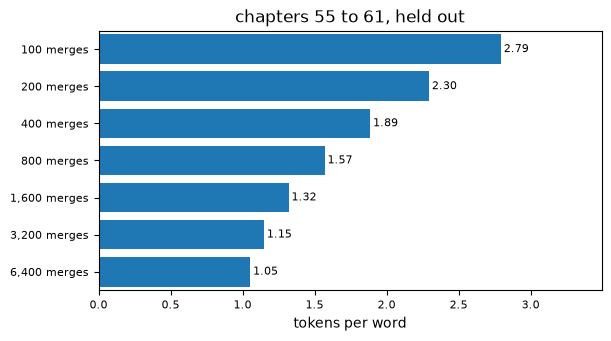

In [8]:
KS = (100, 200, 400, 800, 1600, 3200, 6400)
rates = [per_word(k) for k in KS]
print("saved per doubling: " + "; ".join(f"{a:,} to {b:,} merges, {x - y:.2f} tokens per word" for a, b, x, y in zip(KS, KS[1:], rates, rates[1:])))
bars(f"chapters {FIRST_HELD} to {LAST}, held out", [f"{k:,} merges" for k in KS], rates, "tokens per word")

**Exercise.** Set `K` to the smallest multiple of 100 at which chapters 55
to 61 take under 1.2 tokens per word. How many entries does the vocabulary
then hold, its base symbols included?

In [9]:
K = 1000

whole("K", K, 0, len(merges))
print(f"{K:,} merges: {per_word(K):.3f} tokens per word in chapters {FIRST_HELD} to {LAST}; {len(base)} base symbols and {K:,} merges make {len(base) + K:,} entries")

1,000 merges: 1.475 tokens per word in chapters 55 to 61; 28 base symbols and 1,000 merges make 1,028 entries


### Solution

In [10]:
need = next(k for k in range(0, len(merges) + 1, 100) if per_word(k) < 1.2)
display(Markdown(f"Chapters {FIRST_HELD} to {LAST} take {per_word(need - 100):.3f} tokens per word after {need - 100:,} merges and {per_word(need):.3f} after "
                 f"{need:,}, so `K` is {need:,}: {len(base)} base symbols and {need:,} merges make {len(base) + need:,} entries."
                 + yours("K", 0, len(merges), (need, 1000), lambda k: f" With `K` at {k:,}: {per_word(k):.3f} tokens per word and {len(base) + k:,} entries.")))

Chapters 55 to 61 take 1.207 tokens per word after 2,400 merges and 1.198 after 2,500, so `K` is 2,500: 28 base symbols and 2,500 merges make 2,528 entries.